In [ ]:
#!/usr/bin/env python3
"""Classical fluorescence object detection + Random Forest classification.

Examples:
  python orc1_foci_ml.py detect --input images --output results
  # Edit results/objects_to_label.csv: fill class column (focus/aggregate/artifact)
  python orc1_foci_ml.py train --labels results/objects_to_label.csv --model results/model.joblib
  python orc1_foci_ml.py predict --input images --output predictions --model results/model.joblib

Input: single-plane, single-channel 2D TIFF files (or 2D PNG).
"""

FEATURES = ['area_px','equivalent_diameter_px','eccentricity','solidity',
            'perimeter_px','mean_intensity','max_intensity','min_intensity',
            'intensity_std','contrast','circularity']
CLASSES = {'focus':'#22a7e7','aggregate':'#ff8a33','artifact':'#b5b5b5'}


def load_image(path):
    im = io.imread(str(path))
    if im.ndim != 2:
        raise ValueError(f'{path}: expected a single-channel 2D image, got shape {im.shape}. Extract the correct channel/Z plane first.')
    im = im.astype(np.float32)
    if not np.isfinite(im).all():
        raise ValueError(f'{path}: image contains NaN or infinite values')
    lo, hi = np.percentile(im, [1, 99.9])
    return np.clip((im - lo) / max(hi - lo, 1e-8), 0, 1)


def segment_objects(image, sigma=1.0, min_area=5, threshold_factor=1.0):
    smooth = filters.gaussian(image, sigma=sigma)
    threshold = filters.threshold_otsu(smooth) * threshold_factor
    mask = smooth > threshold
    mask = morphology.remove_small_objects(mask, min_size=min_area)
    # Split touching peaks using a distance-transform watershed.
    distance = ndi.distance_transform_edt(mask)
    peaks = feature.peak_local_max(distance, min_distance=3, labels=mask)
    markers = np.zeros(mask.shape, dtype=np.int32)
    for k, (y, x) in enumerate(peaks, start=1):
        markers[y, x] = k
    if markers.max() == 0:
        return measure.label(mask)
    markers, _ = ndi.label(markers > 0)
    return segmentation.watershed(-distance, markers, mask=mask)


def extract_features(image, labels, filename):
    rows = []
    for region in measure.regionprops(labels, intensity_image=image):
        values = region.intensity_image[region.image]
        area = float(region.area)
        perimeter = float(region.perimeter)
        cy, cx = region.centroid
        y0, x0, y1, x1 = region.bbox
        ring = morphology.binary_dilation(labels == region.label, morphology.disk(3)) & (labels == 0)
        bg = float(np.median(image[ring])) if ring.any() else float(np.median(image))
        rows.append(dict(
            image=filename, object_id=int(region.label), x_px=float(cx), y_px=float(cy),
            bbox_x0=int(x0), bbox_y0=int(y0), bbox_x1=int(x1), bbox_y1=int(y1),
            area_px=area, equivalent_diameter_px=float(region.equivalent_diameter_area),
            eccentricity=float(region.eccentricity), solidity=float(region.solidity),
            perimeter_px=perimeter, mean_intensity=float(values.mean()),
            max_intensity=float(values.max()), min_intensity=float(values.min()),
            intensity_std=float(values.std()), contrast=float(values.mean()-bg),
            circularity=float(4*np.pi*area/perimeter**2) if perimeter > 0 else 0.,
        ))
    return pd.DataFrame(rows)


def images_in(path):
    path = Path(path)
    if path.is_file():
        return [path]
    return sorted(p for p in path.iterdir() if p.suffix.lower() in {'.tif','.tiff','.png'})


def detect_all(args):
    output = Path(args.output)
    output.mkdir(parents=True, exist_ok=True)
    frames = []
    for path in images_in(args.input):
        im = load_image(path)
        labels = segment_objects(im, args.sigma, args.min_area, args.threshold_factor)
        df = extract_features(im, labels, path.name)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from skimage import io, filters, morphology, measure, segmentation
from skimage.feature import peak_local_max
from scipy import ndimage as ndi

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report

Image shape: (512, 512)
Data type: uint16


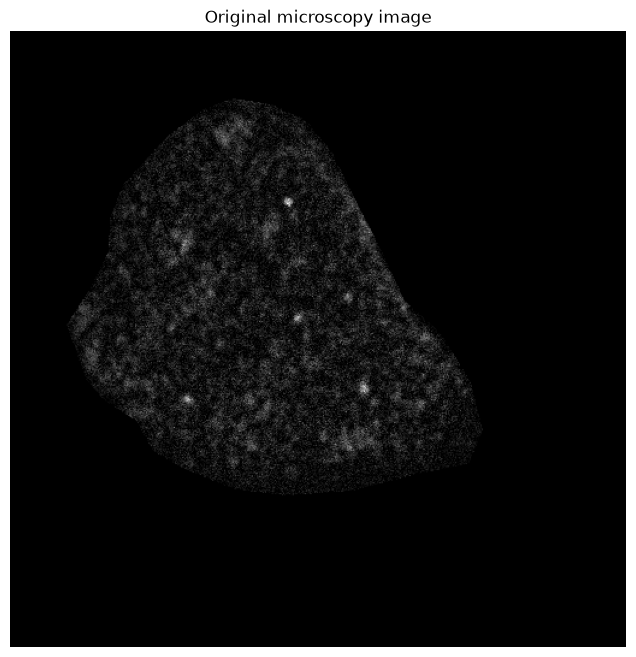

In [5]:
image_path = "test.tif"

image = io.imread(image_path)

print("Image shape:", image.shape)
print("Data type:", image.dtype)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(image, cmap="gray")
ax.set_title("Original microscopy image")
ax.axis("off")

plt.show()

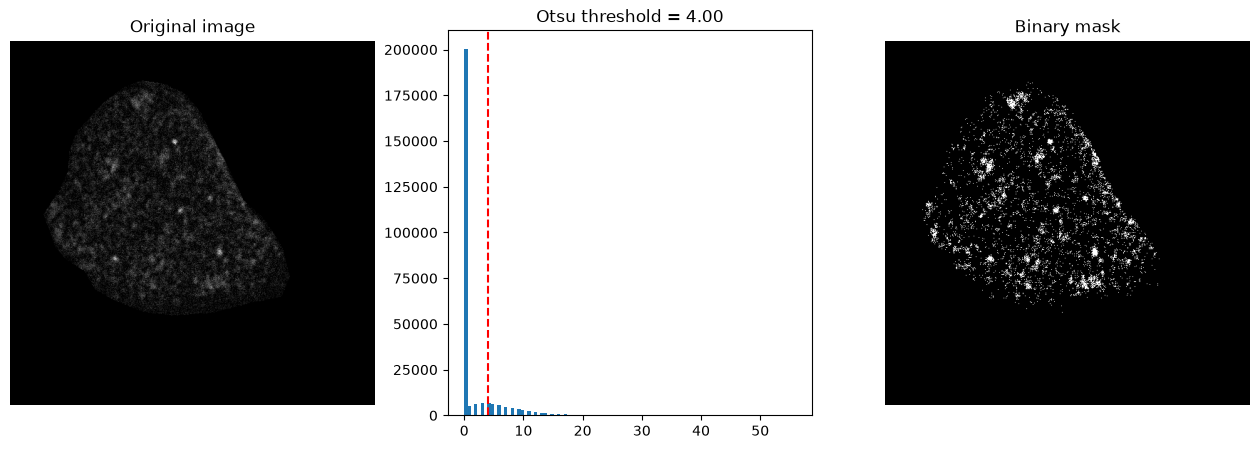

In [15]:
threshold = filters.threshold_otsu(image)
threshold_factor = 3

binary_mask = image > threshold * threshold_factor

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original image")

axes[1].hist(image.ravel(), bins=100)
axes[1].axvline(threshold, color="red", linestyle="--")
axes[1].set_title(f"Otsu threshold = {threshold:.2f}")

axes[2].imshow(binary_mask, cmap="gray")
axes[2].set_title("Binary mask")

for ax in [axes[0], axes[2]]:
    ax.axis("off")

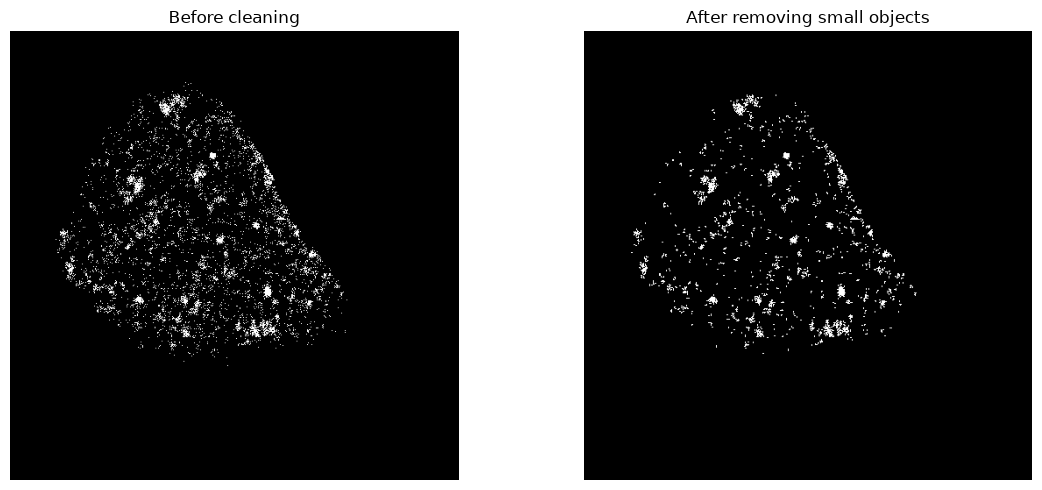

In [19]:
min_area = 2  # pixels

clean_mask = morphology.remove_small_objects(
    binary_mask,
    min_size=min_area
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(binary_mask, cmap="gray")
axes[0].set_title("Before cleaning")

axes[1].imshow(clean_mask, cmap="gray")
axes[1].set_title("After removing small objects")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

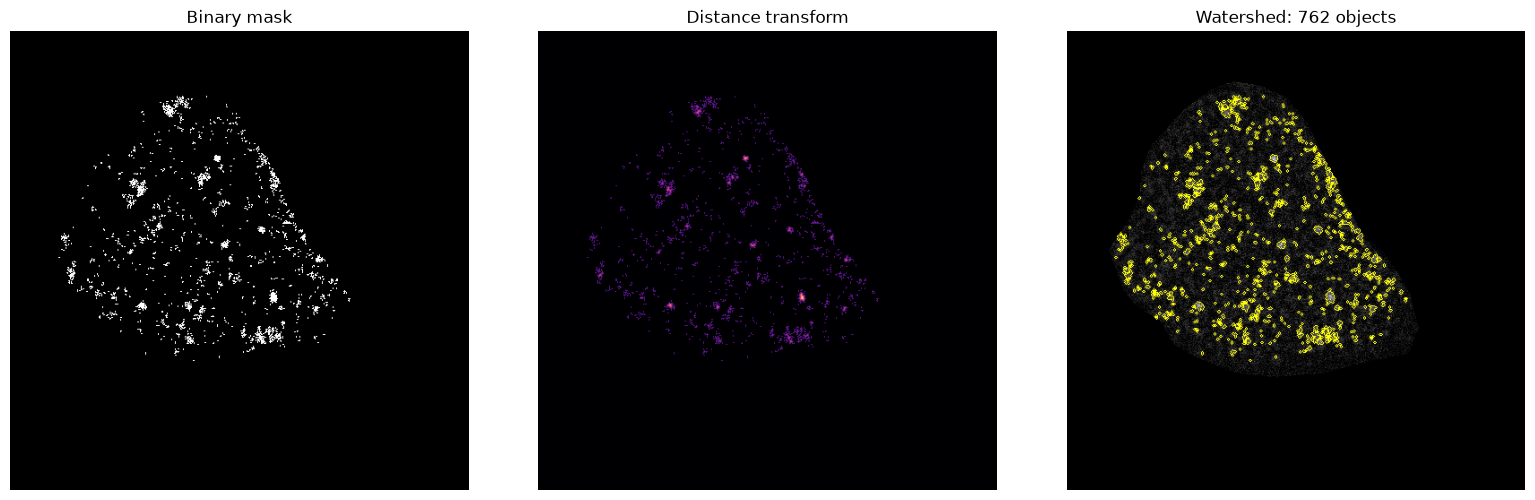

In [21]:
image_float = image.astype(np.float32)

distance = ndi.distance_transform_edt(clean_mask)

# Detect candidate centers
coordinates = peak_local_max(
    distance,
    min_distance=3,
    labels=clean_mask
)

markers = np.zeros_like(clean_mask, dtype=np.int32)

for i, (y, x) in enumerate(coordinates, start=1):
    markers[y, x] = i

labels = segmentation.watershed(
    -distance,
    markers,
    mask=clean_mask
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(clean_mask, cmap="gray")
axes[0].set_title("Binary mask")

axes[1].imshow(distance, cmap="magma")
axes[1].set_title("Distance transform")

axes[2].imshow(
    segmentation.mark_boundaries(
        image_float / (image_float.max() + 1e-8),
        labels
    )
)
axes[2].set_title(f"Watershed: {labels.max()} objects")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
properties = measure.regionprops_table(
    labels,
    intensity_image=image_float,
    properties=[
        "label",
        "area",
        "centroid",
        "equivalent_diameter_area",
        "eccentricity",
        "solidity",
        "perimeter",
        "mean_intensity",
        "max_intensity",
        "min_intensity"
    ]
)

df = pd.DataFrame(properties)

# Circularity: 1 means approximately circular
df["circularity"] = (
    4 * np.pi * df["area"]
    / (df["perimeter"] ** 2 + 1e-8)
)

df["image_id"] = Path(image_path).name

display(df.head())

print("Total detected objects:", len(df))

,label,area,centroid-0,centroid-1,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,circularity,image_id
0,1,80.0,296.737500,293.562500,10.092530,0.713437,0.776699,40.384776,24.025000,50.0,13.0,0.616403,test.tif
1,2,45.0,141.444444,230.866667,7.569398,0.332226,0.849057,25.485281,30.000000,56.0,13.0,0.870650,test.tif
2,3,55.0,306.181818,147.327273,8.368284,0.699367,0.763889,31.349242,22.963636,41.0,13.0,0.703264,test.tif
3,4,22.0,84.045455,176.272727,5.292567,0.567142,0.846154,16.071068,16.500000,22.0,13.0,1.070393,test.tif
4,5,68.0,89.985294,178.161765,9.304853,0.404355,0.693878,42.384776,17.808823,30.0,13.0,0.475663,test.tif


Total detected objects: 762


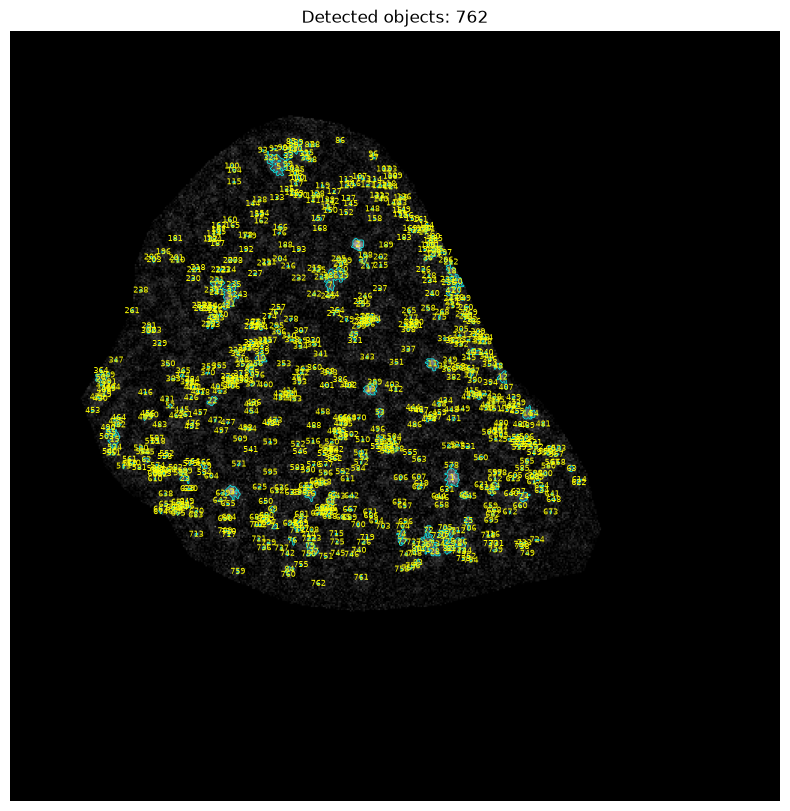

In [23]:
fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(image, cmap="gray")

ax.contour(
    labels > 0,
    levels=[0.5],
    colors="cyan",
    linewidths=0.5
)

for _, row in df.iterrows():
    ax.text(
        row["centroid-1"],
        row["centroid-0"],
        str(int(row["label"])),
        color="yellow",
        fontsize=6,
        ha="center",
        va="center"
    )

ax.set_title(f"Detected objects: {len(df)}")
ax.axis("off")

plt.show()

In [24]:
from matplotlib.patches import Rectangle

def show_object(image, labels, object_id, padding=10):

    region = next(
        r for r in measure.regionprops(labels)
        if r.label == object_id
    )

    min_row, min_col, max_row, max_col = region.bbox

    y0 = max(0, min_row - padding)
    y1 = min(image.shape[0], max_row + padding)

    x0 = max(0, min_col - padding)
    x1 = min(image.shape[1], max_col + padding)

    crop = image[y0:y1, x0:x1]
    mask_crop = labels[y0:y1, x0:x1] == object_id

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(crop, cmap="gray")
    axes[0].set_title(f"Object {object_id}")

    axes[1].imshow(crop, cmap="gray")
    axes[1].contour(mask_crop, levels=[0.5], colors="red")
    axes[1].set_title("Segmentation")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

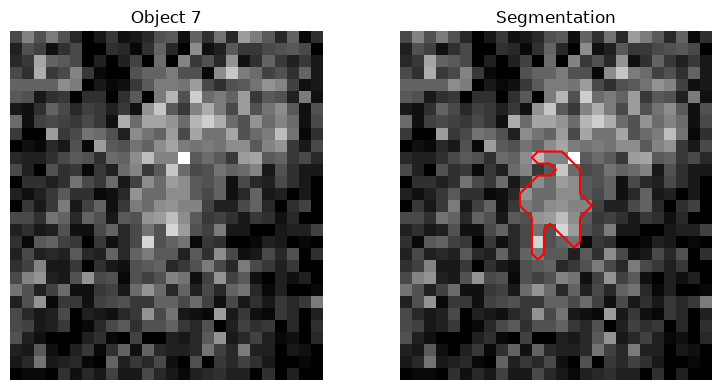

In [27]:
show_object(image, labels, object_id=7)

In [28]:
df["class"] = ""

df.to_csv("foci_features_to_label.csv", index=False)

In [33]:
df_labeled = pd.read_csv("foci_features_to_label.csv")


In [34]:
df_labeled

,label,area,centroid-0,centroid-1,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,circularity,image_id,class
0,1,80.0,296.737500,293.562500,10.092530,0.713437,0.776699,40.384776,24.025000,50.0,13.0,6.164026e-01,test.tif,NaN
1,2,45.0,141.444444,230.866667,7.569398,0.332226,0.849057,25.485281,30.000000,56.0,13.0,8.706498e-01,test.tif,NaN
2,3,55.0,306.181818,147.327273,8.368284,0.699367,0.763889,31.349242,22.963636,41.0,13.0,7.032641e-01,test.tif,NaN
3,4,22.0,84.045455,176.272727,5.292567,0.567142,0.846154,16.071068,16.500000,22.0,13.0,1.070393e+00,test.tif,NaN
4,5,68.0,89.985294,178.161765,9.304853,0.404355,0.693878,42.384776,17.808823,30.0,13.0,4.756626e-01,test.tif,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
757,758,2.0,357.500000,260.000000,1.595769,1.000000,1.000000,0.000000,14.500000,15.0,14.0,2.513274e+09,test.tif,NaN
758,759,3.0,359.000000,151.000000,1.954410,1.000000,1.000000,1.000000,13.000000,13.0,13.0,3.769911e+01,test.tif,NaN
759,760,2.0,361.000000,184.500000,1.595769,1.000000,1.000000,0.000000,17.000000,21.0,13.0,2.513274e+09,test.tif,NaN
760,761,3.0,363.000000,233.000000,1.954410,1.000000,1.000000,1.000000,14.666667,16.0,13.0,3.769911e+01,test.tif,NaN


In [30]:
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "solidity",
    "perimeter",
    "mean_intensity",
    "max_intensity",
    "min_intensity",
    "circularity"
]

X = df_labeled[features]
y = df_labeled["class"]

# Train using manually labeled objects
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X, y)

print("Random Forest trained successfully!")

ValueError: Found array with 0 sample(s) (shape=(0, 9)) while a minimum of 1 is required by RandomForestClassifier.